# 05 — Logistic Regression for high-demand classification

**Classification question:** Can route, airline, distance, and month help identify route-airline-month records with relatively high passenger demand?

We define “high demand” using the 75th percentile of **2025 training records**. The threshold is then held fixed for the 2026 test set to avoid letting test information influence the label definition. This is a binary teaching label, not an official BTS category.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, classification_report)

df = pd.read_csv(Path("data/processed/air_passenger_monthly.csv"))
df["MONTH_SIN"] = np.sin(2*np.pi*df.MONTH/12)
df["MONTH_COS"] = np.cos(2*np.pi*df.MONTH/12)
train_all = df[df.YEAR.eq(2025)].copy()
test_all = df[df.YEAR.eq(2026)].copy()
threshold = train_all.PASSENGERS.quantile(.75)
train_all["HIGH_DEMAND"] = (train_all.PASSENGERS >= threshold).astype(int)
test_all["HIGH_DEMAND"] = (test_all.PASSENGERS >= threshold).astype(int)
print(f"2025-only high-demand threshold: {threshold:,.0f} passengers")
print("Training label share:", train_all.HIGH_DEMAND.mean().round(3))
print("2026 label share:", test_all.HIGH_DEMAND.mean().round(3))

2025-only high-demand threshold: 4,310 passengers
Training label share: 0.25
2026 label share: 0.247


## Prepare features and fit
A reproducible sample makes this notebook workable on a standard laptop. We do not include passenger count itself as an input, because it defines the target and would leak the answer. Class weighting helps the model pay attention to the smaller high-demand group.

In [2]:
train = train_all.sample(n=min(120_000, len(train_all)), random_state=42)
test = test_all.sample(n=min(80_000, len(test_all)), random_state=42)
categorical = ["ORIGIN", "DEST", "UNIQUE_CARRIER"]
numeric = ["DISTANCE", "MONTH_SIN", "MONTH_COS"]
prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=30), categorical),
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), numeric)
])
clf = Pipeline([
    ("features", prep),
    ("logistic", LogisticRegression(max_iter=500, class_weight="balanced", solver="liblinear"))
])
clf.fit(train[categorical + numeric], train.HIGH_DEMAND)

Pipeline(steps=[('features',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                min_frequency=30),
                                                  ['ORIGIN', 'DEST',
                                                   'UNIQUE_CARRIER']),
                                                 ('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['DISTANCE', 'MONTH_SIN',
                                                   'MONTH_COS'])])),
                ('logistic',
                 LogisticReg

## Evaluate on 2026 holdout records
Accuracy alone can be misleading when one class is less common. We report precision, recall, F1, ROC-AUC, and the confusion matrix so the trade-offs are visible.

Accuracy:  0.791
Precision: 0.548
Recall:    0.858
F1 score:  0.669
ROC-AUC:   0.895
              precision    recall  f1-score   support

      Normal       0.94      0.77      0.85     60281
        High       0.55      0.86      0.67     19719

    accuracy                           0.79     80000
   macro avg       0.75      0.81      0.76     80000
weighted avg       0.85      0.79      0.80     80000



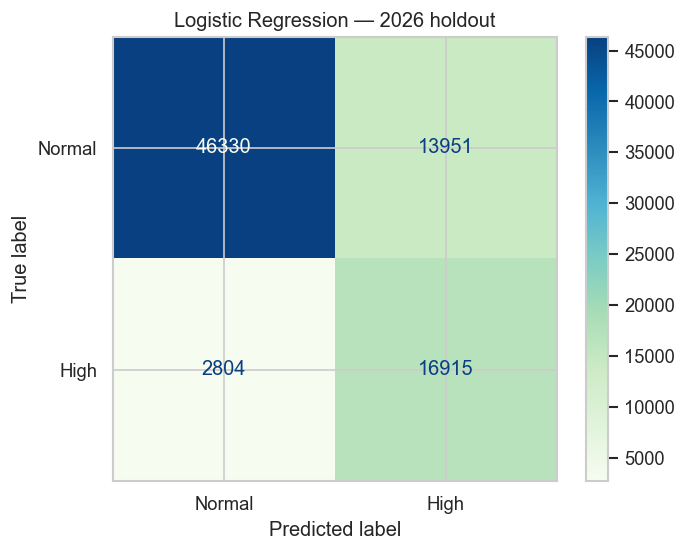

In [3]:
pred = clf.predict(test[categorical + numeric])
prob = clf.predict_proba(test[categorical + numeric])[:, 1]
print(f"Accuracy:  {accuracy_score(test.HIGH_DEMAND, pred):.3f}")
print(f"Precision: {precision_score(test.HIGH_DEMAND, pred, zero_division=0):.3f}")
print(f"Recall:    {recall_score(test.HIGH_DEMAND, pred, zero_division=0):.3f}")
print(f"F1 score:  {f1_score(test.HIGH_DEMAND, pred, zero_division=0):.3f}")
print(f"ROC-AUC:   {roc_auc_score(test.HIGH_DEMAND, prob):.3f}")
print(classification_report(test.HIGH_DEMAND, pred, target_names=["Normal", "High"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(test.HIGH_DEMAND, pred, display_labels=["Normal", "High"], cmap="GnBu")
plt.title("Logistic Regression — 2026 holdout")
plt.show()

### Plain-language result
The classifier estimates whether a route-airline-month is in the higher-demand group based on its route and calendar information. It does not identify individual passengers or predict live flights. A strict report should discuss false alarms (normal records predicted high) and missed peaks (high records predicted normal), not accuracy alone.
